In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/water_potability_cleaned.csv")

print("Dataset shape:", df.shape)

Dataset shape: (3276, 10)


In [2]:
features = [
    "ph",
    "Hardness",
    "Solids",
    "Chloramines",
    "Sulfate",
    "Conductivity",
    "Organic_carbon",
    "Trihalomethanes",
    "Turbidity"
]

In [3]:
print("\nSkewness:")
print(df[features].skew().sort_values(ascending=False))


Skewness:
Solids             0.621634
Conductivity       0.264490
ph                 0.041266
Organic_carbon     0.025533
Turbidity         -0.007817
Chloramines       -0.012098
Sulfate           -0.027278
Hardness          -0.039342
Trihalomethanes   -0.087289
dtype: float64


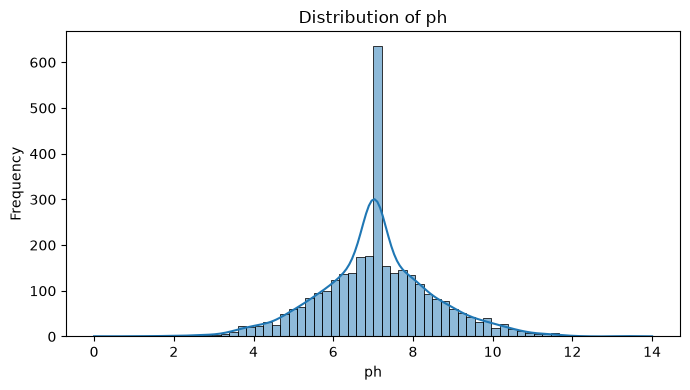

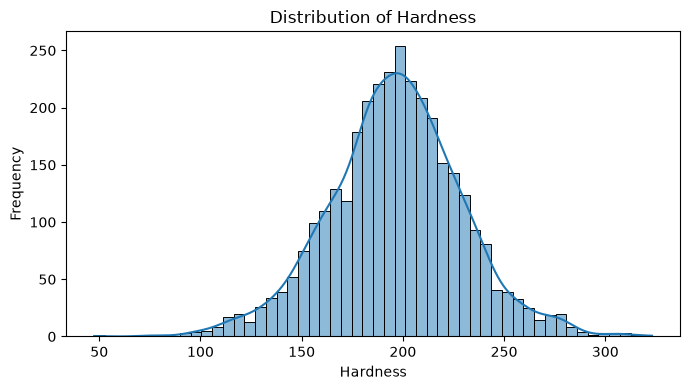

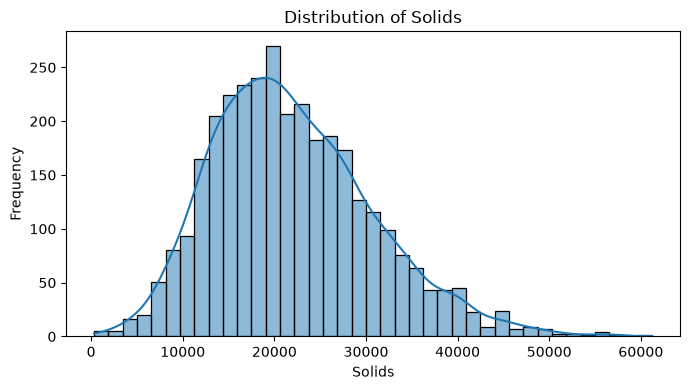

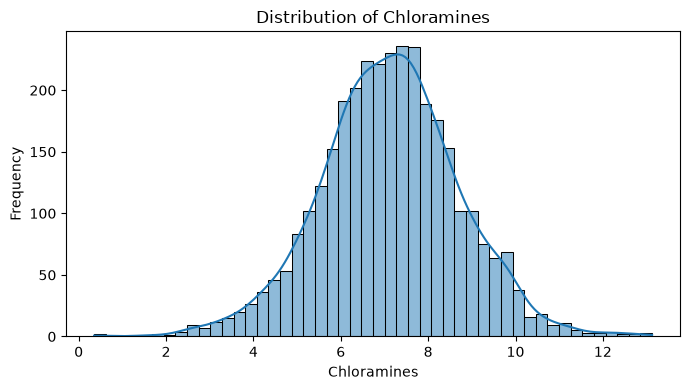

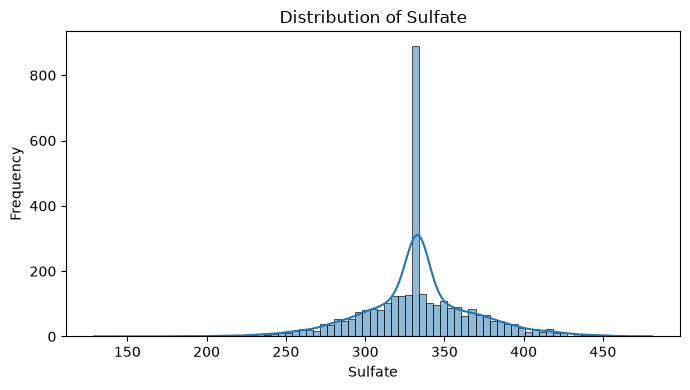

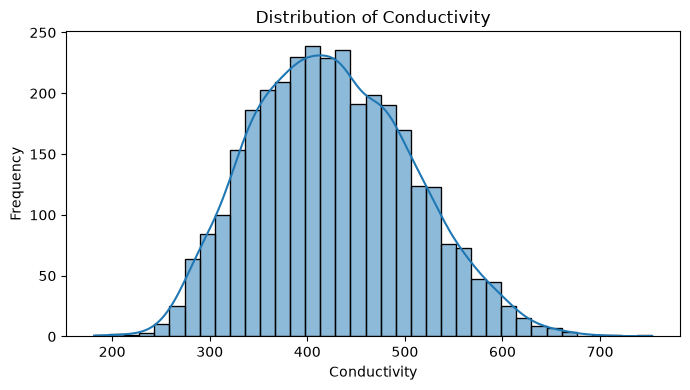

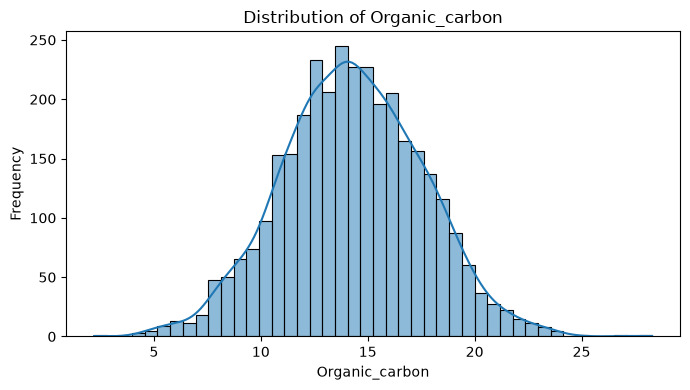

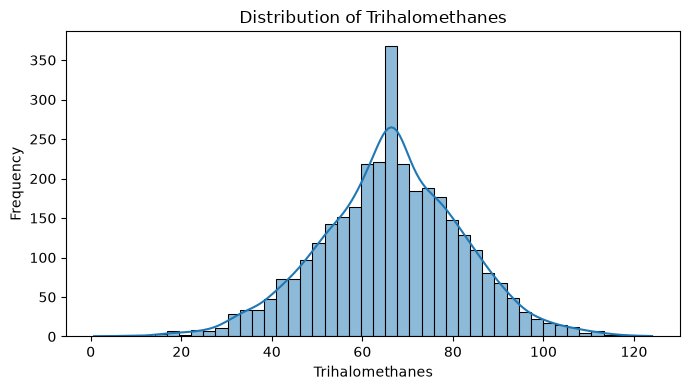

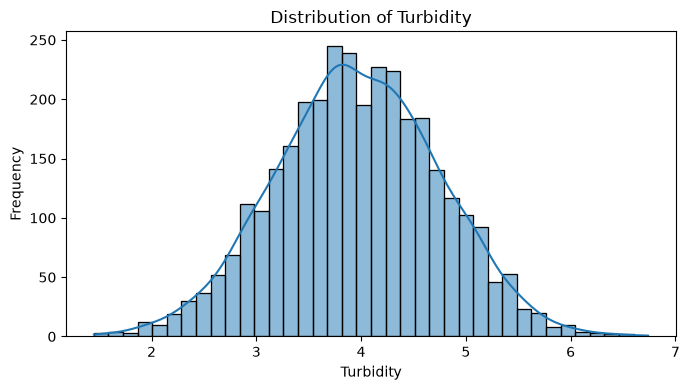

In [4]:
for feature in features:

    plt.figure(figsize=(7, 4))

    sns.histplot(
        data=df,
        x=feature,
        kde=True
    )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

In [5]:
print("\nOutlier Analysis:")

for feature in features:

    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ]

    print(
        f"{feature}: "
        f"{len(outliers)} potential outliers"
    )


Outlier Analysis:
ph: 142 potential outliers
Hardness: 83 potential outliers
Solids: 47 potential outliers
Chloramines: 61 potential outliers
Sulfate: 264 potential outliers
Conductivity: 11 potential outliers
Organic_carbon: 25 potential outliers
Trihalomethanes: 54 potential outliers
Turbidity: 19 potential outliers


In [6]:
outlier_results = []

for feature in features:

    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    count = (
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ).sum()

    percentage = (count / len(df)) * 100

    outlier_results.append({
        "Feature": feature,
        "Outlier Count": count,
        "Outlier Percentage": percentage
    })

outlier_df = pd.DataFrame(outlier_results)

print("\nOutlier Summary:")
print(outlier_df)


Outlier Summary:
           Feature  Outlier Count  Outlier Percentage
0               ph            142            4.334554
1         Hardness             83            2.533578
2           Solids             47            1.434676
3      Chloramines             61            1.862027
4          Sulfate            264            8.058608
5     Conductivity             11            0.335775
6   Organic_carbon             25            0.763126
7  Trihalomethanes             54            1.648352
8        Turbidity             19            0.579976


In [7]:
print("\nFeature ranges:")

for feature in features:

    minimum = df[feature].min()
    maximum = df[feature].max()

    print(
        f"{feature}: "
        f"min={minimum:.2f}, "
        f"max={maximum:.2f}"
    )


Feature ranges:
ph: min=0.00, max=14.00
Hardness: min=47.43, max=323.12
Solids: min=320.94, max=61227.20
Chloramines: min=0.35, max=13.13
Sulfate: min=129.00, max=481.03
Conductivity: min=181.48, max=753.34
Organic_carbon: min=2.20, max=28.30
Trihalomethanes: min=0.74, max=124.00
Turbidity: min=1.45, max=6.74


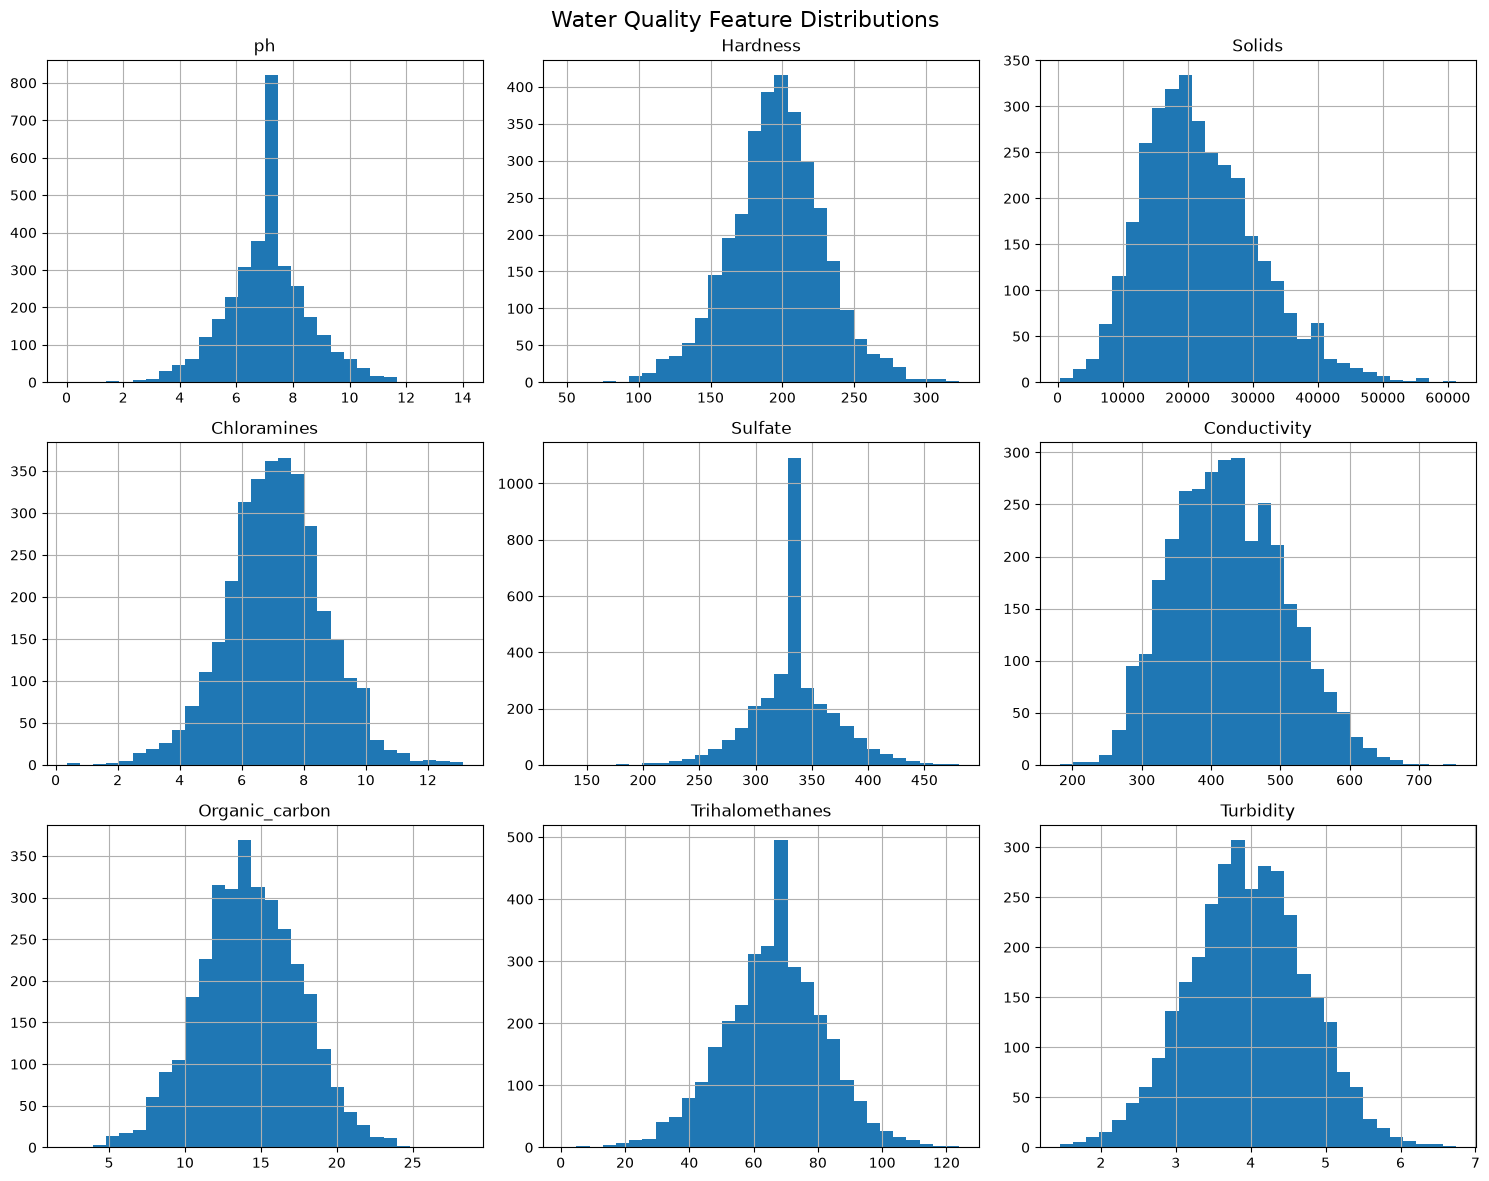

In [8]:
df[features].hist(
    figsize=(15, 12),
    bins=30
)

plt.suptitle(
    "Water Quality Feature Distributions",
    fontsize=16
)

plt.tight_layout()
plt.show()